# Pearson mı, Spearman mı?

**Canlı Ders · code2work DS · Modül 7 — İstatistiğe Giriş**

> *"Bu iki yöntemin ne amaçla kullanıldığını tam olarak anlayamadım. Hangi durumda hangi yöntemi tercih etmemiz gerektiğini örneklerle açıklayabilir misiniz?"*

Bugün:
1. Derstekine dönüş — neden ikisi aynı çıktı?
2. İkisi **neyi** ölçüyor?
3. Üç örnek: **eğri** ilişki · **aykırı değer** · **sıralı veri**
4. Karar tablosu

---
## 1) Derstekine dönelim

Derste korelasyonu `corr()` ile hesapladık, `method` parametresiyle yöntemi seçtik. Aynı veride ikisini yan yana koyalım:

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

x = pd.Series([10, 20, 30, 40, 50])
y = pd.Series([12, 24, 33, 48, 55])

print('Pearson :', round(x.corr(y, method='pearson'), 3))
print('Spearman:', round(x.corr(y, method='spearman'), 3))

Pearson : 0.995
Spearman: 1.0


İkisi de neredeyse **1**. Peki o zaman neden iki ayrı yöntem var?

Çünkü bu veri **çok uslu**: noktalar neredeyse dümdüz bir çizgi üstünde. Böyle veride ikisi hep aynı şeyi söyler.
Farkı görmek için verinin biraz "yaramazlık" yapması lazım.

---
## 2) İkisi neyi ölçüyor?

| | Sorduğu soru | Benzetme |
|---|---|---|
| **Pearson** | Noktalar **düz bir çizgiye** ne kadar yakın? | Cetvel tutuyor |
| **Spearman** | Biri **artınca** öteki de **artıyor mu**? (ne kadar arttığı önemli değil) | Sadece **sıraya** bakıyor |

> Spearman sayıların kendisine değil, **sırasına** bakar: "en küçük, ikinci, üçüncü..."
> Bu yüzden *"ne kadar"* değil, *"aynı yöne mi gidiyor"* sorusunu cevaplar.

Grafik çizmek için küçük bir yardımcı fonksiyon:

In [7]:
def ciz(a, b, baslik, x_ad, y_ad):
    plt.figure(figsize=(5, 3.2))
    plt.scatter(a, b, s=60)
    plt.title(f"{baslik}\nPearson = {a.corr(b):.6f}   |   Spearman = {a.corr(b, method='spearman'):.6f}")
    plt.xlabel(x_ad)
    plt.ylabel(y_ad)
    plt.grid(alpha=0.3)
    plt.show()

---
## 3a) Artıyor ama düz değil: Instagram takipçisi

Bir hesap her ay takipçisini **ikiye katlıyor**. Ay arttıkça takipçi **hep** artıyor — ama çizgi düz değil, **kıvrılıp** yukarı fırlıyor.

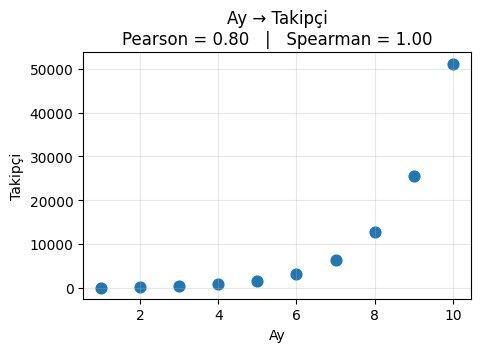

In [5]:
ay = pd.Series(range(1, 11))
takipci = pd.Series([100, 200, 400, 800, 1600, 3200, 6400, 12800, 25600, 51200])

ciz(ay, takipci, 'Ay → Takipçi', 'Ay', 'Takipçi')

- **Spearman = 1** → "Ay arttıkça takipçi **her seferinde** arttı." Mükemmel aynı yön. ✅
- **Pearson ≈ 0.80** → "Noktalar düz çizgiye o kadar yakın değil." Çünkü çizgi eğri.

> İlişki **kusursuz** ama Pearson bunu tam göremiyor. Eğri ilişkide → **Spearman**.

---
## 3b) Aykırı değer: tek bir yanlış kayıt

Deneyim yılı ve maaş (bin TL). Normalde deneyim arttıkça maaş düzenli artıyor:

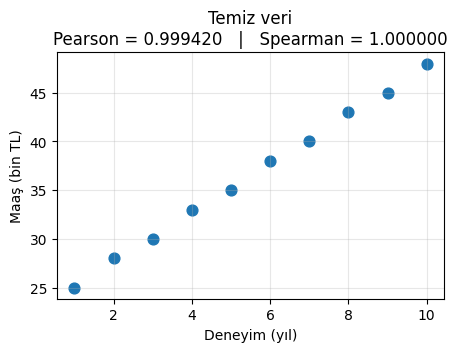

In [8]:
deneyim = pd.Series([1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
maas    = pd.Series([25, 28, 30, 33, 35, 38, 40, 43, 45, 48])

ciz(deneyim, maas, 'Temiz veri', 'Deneyim (yıl)', 'Maaş (bin TL)')

İkisi de ≈ 1. Şimdi veri girerken birisi **2 yıllık** çalışanın maaşını `28` yerine yanlışlıkla `250` yazmış olsun:

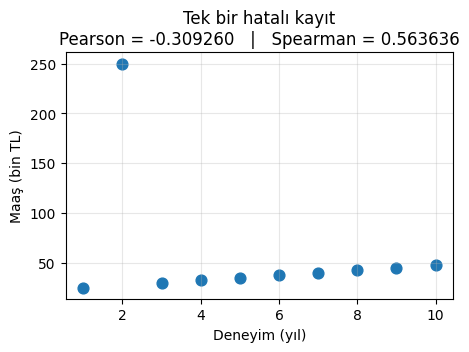

In [9]:
maas_hatali = maas.copy()
maas_hatali[1] = 250          # tek bir satır bozuldu

ciz(deneyim, maas_hatali, 'Tek bir hatalı kayıt', 'Deneyim (yıl)', 'Maaş (bin TL)')

- **Pearson: 1 → −0.31** 😱 Tek bir nokta yüzünden ilişki **ters dönmüş** gibi görünüyor!
- **Spearman: 1 → 0.56** → O da etkilendi ama **"hâlâ aynı yönde artıyor"** diyor.

Neden? Pearson **sayının büyüklüğüne** bakar: 250, 48'den çok çok büyük → çizgiyi kendine çeker.
Spearman sadece **sıraya** bakar: 250 için "en büyük olan" der, ne kadar büyük olduğunu umursamaz.

> Aykırı değer varsa → **Spearman** daha güvenilir. (Ya da önce aykırı değeri temizle — derste IQR ile yaptığımız gibi.)

---
## 3c) Sıralı veri: anket puanı

Müşteriye "Memnuniyetiniz?" diye soruyoruz: **1 = Çok kötü … 5 = Çok iyi**. Bir de o müşterinin yıl içindeki alışveriş sayısı var.

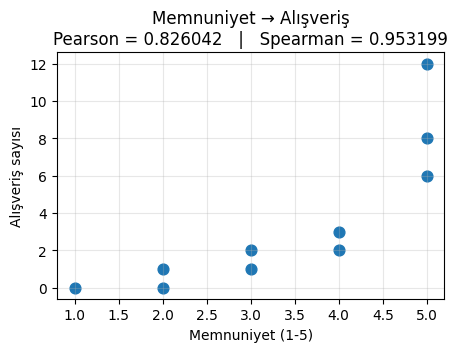

In [10]:
memnuniyet = pd.Series([1, 2, 2, 3, 3, 4, 4, 5, 5, 5])
alisveris  = pd.Series([0, 1, 0, 2, 1, 3, 2, 6, 8, 12])

ciz(memnuniyet, alisveris, 'Memnuniyet → Alışveriş', 'Memnuniyet (1-5)', 'Alışveriş sayısı')

Buradaki 1-2-3-4-5 gerçek bir ölçü değil, bir **sıra**:
"Çok iyi" ile "İyi" arasındaki fark, "Kötü" ile "Orta" arasındaki farkla **aynı mı?** Bilemeyiz.

Pearson sayıları gerçek ölçüymüş gibi kullanır; Spearman sadece "hangisi daha yüksek" der.

> Anket puanı, yarış sıralaması, eğitim seviyesi (ilkokul < lise < üniversite) gibi **sıralı** veride → **Spearman**.